In [1]:
import pandas as pd
import numpy as np
import joblib
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Cố định kết quả ngẫu nhiên
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

In [2]:
# Đọc dữ liệu đã chuẩn hóa
X_train = pd.read_csv("../data/processed/X_train_scaled.csv")
X_val = pd.read_csv("../data/processed/X_val_scaled.csv")
X_test = pd.read_csv("../data/processed/X_test_scaled.csv")

# Đọc nhãn
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_val = pd.read_csv("../data/processed/y_val.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (396332, 79) (396332,)
Validation: (98194, 79) (98194,)
Test: (100117, 79) (100117,)


In [3]:
# Chỉ lấy các giao dịch bình thường để huấn luyện
X_train_normal = X_train[y_train == 0].copy()

print("Kích thước dữ liệu Train ban đầu:", X_train.shape)
print("Kích thước dữ liệu Train bình thường:", X_train_normal.shape)

print("\nSố giao dịch bình thường:", len(X_train_normal))
print("Số đặc trưng:", X_train_normal.shape[1])

Kích thước dữ liệu Train ban đầu: (396332, 79)
Kích thước dữ liệu Train bình thường: (391292, 79)

Số giao dịch bình thường: 391292
Số đặc trưng: 79


In [4]:
# Số đặc trưng đầu vào
input_dim = X_train_normal.shape[1]

# Lớp đầu vào
input_layer = Input(shape=(input_dim,))

# Encoder: nén dữ liệu
encoder = Dense(64, activation="relu")(input_layer)
encoder = Dense(32, activation="relu")(encoder)
encoder = Dense(16, activation="relu")(encoder)

# Decoder: tái tạo dữ liệu
decoder = Dense(32, activation="relu")(encoder)
decoder = Dense(64, activation="relu")(decoder)
output_layer = Dense(input_dim, activation="linear")(decoder)

# Tạo Autoencoder
autoencoder = Model(inputs=input_layer, outputs=output_layer)

# Cấu hình huấn luyện
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

# Hiển thị cấu trúc mô hình
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 79)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 79)             │         5,135 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,519 (60.62 KB)

 Trainable params: 15,519 (60.62 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [6]:
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=50,
    batch_size=256,
    shuffle=True,
    validation_data=(
        X_val[y_val == 0],
        X_val[y_val == 0]
    ),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
1529/1529 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - loss: 0.0049 - val_loss: 0.0010
Epoch 2/50
1529/1529 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 9.2610e-04 - val_loss: 7.8024e-04
Epoch 3/50
1529/1529 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 7.6842e-04 - val_loss: 6.9149e-04
Epoch 4/50
1529/1529 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 6.9474e-04 - val_loss: 6.5483e-04
Epoch 5/50
1529/1529 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 6.3954e-04 - val_loss: 6.0000e-04
Epoch 6/50
1529/1529 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 6.0691e-04 - val_loss: 5.7463e-04
Epoch 7/50
1529/1529 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 5.8855e-04 - val_loss: 5.6349e-04
Epoch 8/50
1529/1529 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - loss: 5.6812e-04 - val_loss: 5.5376e-04
Epoch 9/50
1529/1529 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 5.5137e-04 - val_loss: 5.3834e-04
Epoch 10/50
1529/1529 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 5.3418e-04 - val_loss: 5.6751e-04
Epoch 11/50
1529/1529 ━━━━━━━━━━━━━━━━━━━━ 2s

In [7]:
print("Số epoch thực tế:", len(history.history["loss"]))

print(
    "Training Loss tốt nhất:",
    min(history.history["loss"])
)

print(
    "Validation Loss tốt nhất:",
    min(history.history["val_loss"])
)

Số epoch thực tế: 22
Training Loss tốt nhất: 0.00041229871567338705
Validation Loss tốt nhất: 0.000510308425873518


In [8]:
# Tái tạo dữ liệu Validation
val_reconstructed = autoencoder.predict(X_val, verbose=0)

# Tính MSE cho từng giao dịch
val_errors = np.mean(
    np.square(X_val.values - val_reconstructed),
    axis=1
)

print("5 Reconstruction Error đầu tiên:")
print(val_errors[:5])

print("\nSai số nhỏ nhất:", val_errors.min())
print("Sai số lớn nhất:", val_errors.max())
print("Sai số trung bình:", val_errors.mean())

5 Reconstruction Error đầu tiên:
[3.20674489e-05 2.85612241e-05 3.01610035e-05 1.74096859e-04
 3.53256188e-05]

Sai số nhỏ nhất: 1.791404274531543e-05
Sai số lớn nhất: 0.07377528525947441
Sai số trung bình: 0.0006521355240052827


In [9]:
val_error_df = pd.DataFrame({
    "Reconstruction_Error": val_errors,
    "Fraud": y_val.values
})

print(
    val_error_df.groupby("Fraud")["Reconstruction_Error"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

       count      mean    median       std       min       max
Fraud                                                         
0      97114  0.000510  0.000069  0.002440  0.000018  0.056033
1       1080  0.013405  0.014279  0.011385  0.000076  0.073775


In [10]:
from sklearn.metrics import precision_recall_curve
import numpy as np

# Tính Precision, Recall tại nhiều ngưỡng khác nhau
precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_errors
)

# Tính F1-score tương ứng với từng ngưỡng
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

# Tìm ngưỡng có F1-score cao nhất
best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]

print("Ngưỡng tối ưu:", best_threshold)
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])
print("F1-score:", f1_scores[best_idx])

Ngưỡng tối ưu: 0.01415283392164206
Precision: 0.3628482972136223
Recall: 0.5425925925925926
F1-score: 0.43487940625994814


In [11]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# 1. Tính Reconstruction Error trên tập Test
test_reconstructed = autoencoder.predict(X_test, verbose=0)

test_errors = np.mean(
    np.square(X_test.values - test_reconstructed),
    axis=1
)

# 2. Dự đoán bằng ngưỡng đã chọn từ Validation
y_test_pred = (test_errors >= best_threshold).astype(int)

# 3. Tính các chỉ số đánh giá
print("Threshold:", best_threshold)
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-score:", f1_score(y_test, y_test_pred))
print("PR-AUC:", average_precision_score(y_test, test_errors))

# Tính Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Threshold: 0.01415283392164206
Precision: 0.3411351667641896
Recall: 0.5398148148148149
F1-score: 0.4180709931875224
PR-AUC: 0.3206326742224738

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     99037
           1       0.34      0.54      0.42      1080

    accuracy                           0.98    100117
   macro avg       0.67      0.76      0.70    100117
weighted avg       0.99      0.98      0.99    100117



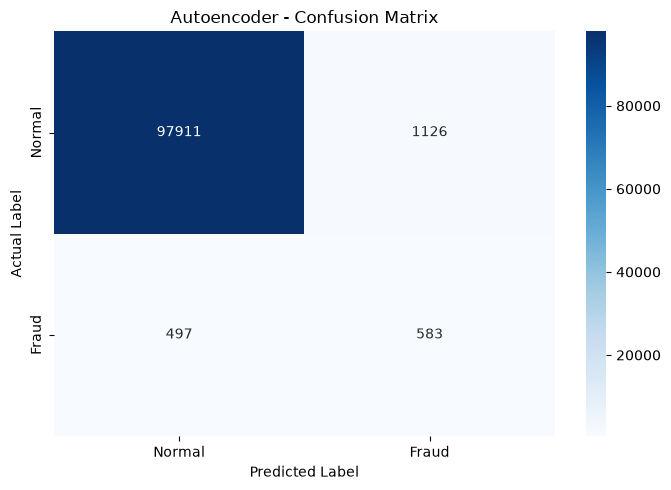

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Autoencoder - Confusion Matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("Autoencoder - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [13]:
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Tổng hợp các chỉ số đánh giá
evaluation_results = pd.DataFrame({
    "Chỉ số đánh giá": [
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Giá trị": [
        precision_score(y_test, y_test_pred, zero_division=0),
        recall_score(y_test, y_test_pred, zero_division=0),
        f1_score(y_test, y_test_pred, zero_division=0),
        roc_auc_score(y_test, test_errors),
        average_precision_score(y_test, test_errors)
    ]
})

# Đánh số thứ tự từ 1
evaluation_results.index = range(1, len(evaluation_results) + 1)

# Hiển thị kết quả
print("Kết quả đánh giá mô hình Autoencoder")

display(
    evaluation_results.style
    .format({"Giá trị": "{:.5f}"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "center")]},
        {"selector": "td", "props": [("text-align", "center")]}
    ])
)

Kết quả đánh giá mô hình Autoencoder


,Chỉ số đánh giá,Giá trị
1,Precision,0.34114
2,Recall,0.53981
3,F1-Score,0.41807
4,ROC-AUC,0.86814
5,PR-AUC,0.32063


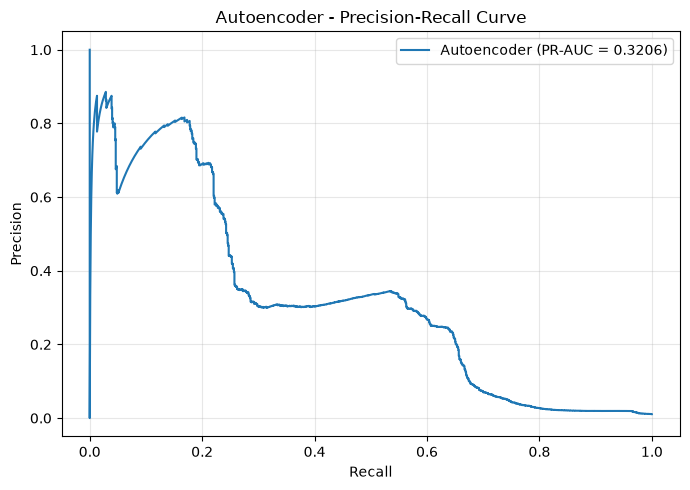

In [14]:
from sklearn.metrics import precision_recall_curve

# Autoencoder - Precision-Recall Curve

precision_values, recall_values, _ = precision_recall_curve(
    y_test,
    test_errors
)

plt.figure(figsize=(7, 5))

pr_auc = average_precision_score(y_test, test_errors)

plt.plot(
    recall_values,
    precision_values,
    label=f"Autoencoder (PR-AUC = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Autoencoder - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

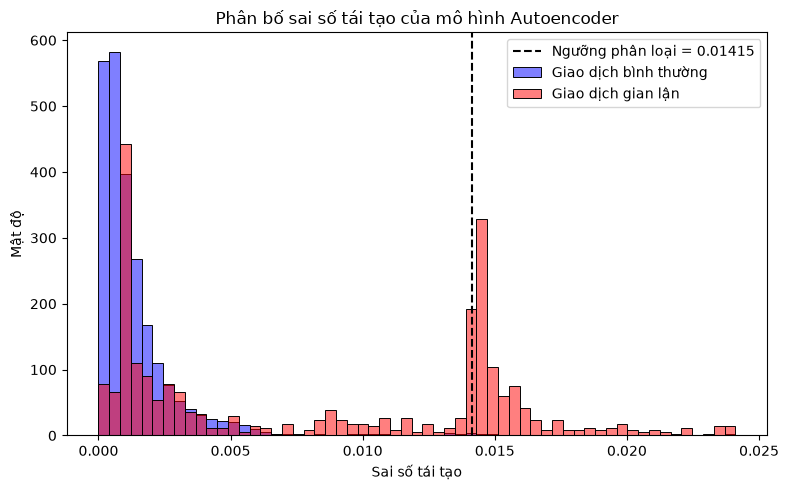

In [15]:
# Phân bố sai số tái tạo của mô hình Autoencoder

plt.figure(figsize=(8, 5))

bins = np.linspace(0, np.percentile(test_errors, 99.5), 60)

sns.histplot(
    test_errors[y_test == 0],
    bins=bins,
    color="blue",
    label="Giao dịch bình thường",
    stat="density",
    alpha=0.5
)

sns.histplot(
    test_errors[y_test == 1],
    bins=bins,
    color="red",
    label="Giao dịch gian lận",
    stat="density",
    alpha=0.5
)

plt.axvline(
    best_threshold,
    color="black",
    linestyle="--",
    label=f"Ngưỡng phân loại = {best_threshold:.5f}"
)

plt.title("Phân bố sai số tái tạo của mô hình Autoencoder")
plt.xlabel("Sai số tái tạo")
plt.ylabel("Mật độ")
plt.legend()

plt.tight_layout()
plt.show()

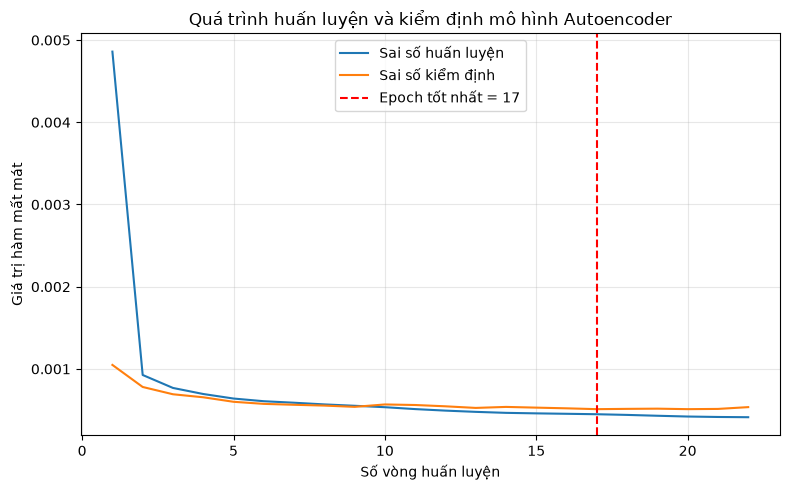

In [18]:
import matplotlib.pyplot as plt
import numpy as np

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = np.arange(1, len(train_loss) + 1)
best_epoch = np.argmin(val_loss) + 1

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_loss, label="Sai số huấn luyện")
plt.plot(epochs, val_loss, label="Sai số kiểm định")

plt.axvline(
    best_epoch,
    color="red",
    linestyle="--",
    label=f"Epoch tốt nhất = {best_epoch}"
)

plt.xlabel("Số vòng huấn luyện")
plt.ylabel("Giá trị hàm mất mát")
plt.title("Quá trình huấn luyện và kiểm định mô hình Autoencoder")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
import joblib

# Lưu mô hình Autoencoder
autoencoder.save("../models/autoencoder.keras")

# Lưu ngưỡng phân loại đã chọn trên Validation
with open("../models/autoencoder_threshold.txt", "w") as f:
    f.write(str(best_threshold))

print("Đã lưu Autoencoder và threshold thành công!")

Đã lưu Autoencoder và threshold thành công!
